In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("../datasets/bigbasket/BigBasket.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 8208
Columns: 9


In [7]:
df.head()

,ProductName,Brand,Price,DiscountPrice,Image_Url,Quantity,Category,SubCategory,Absolute_Url
0,Onion (Loose),Fresho,69.75,52.0,https://www.bigbasket.com/media/uploads/p/l/40...,2 kg,Fruits & Vegetables,"Potato, Onion & Tomato",https://www.bigbasket.com/pd/40075537/fresho-o...
1,Onion,Fresho,174.35,130.0,https://www.bigbasket.com/media/uploads/p/l/12...,5 kg,Fruits & Vegetables,"Potato, Onion & Tomato",https://www.bigbasket.com/pd/1201414/fresho-on...
2,Onion (Loose),Fresho,34.87,26.0,https://www.bigbasket.com/media/uploads/p/l/10...,1 kg,Fruits & Vegetables,"Potato, Onion & Tomato",https://www.bigbasket.com/pd/10000148/fresho-o...
3,Onion,Fresho,69.74,52.0,https://www.bigbasket.com/media/uploads/p/l/12...,2 kg,Fruits & Vegetables,"Potato, Onion & Tomato",https://www.bigbasket.com/pd/1201413/fresho-on...
4,Onion (Loose),Fresho,174.37,129.0,https://www.bigbasket.com/media/uploads/p/l/10...,5 kg,Fruits & Vegetables,"Potato, Onion & Tomato",https://www.bigbasket.com/pd/10000150/fresho-o...


In [9]:
print(df.columns.tolist())

['ProductName', 'Brand', 'Price', 'DiscountPrice', 'Image_Url', 'Quantity', 'Category', 'SubCategory', 'Absolute_Url']


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8208 entries, 0 to 8207
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ProductName    8208 non-null   object 
 1   Brand          8208 non-null   object 
 2   Price          8208 non-null   float64
 3   DiscountPrice  8208 non-null   float64
 4   Image_Url      8208 non-null   object 
 5   Quantity       8208 non-null   object 
 6   Category       8208 non-null   object 
 7   SubCategory    8208 non-null   object 
 8   Absolute_Url   8208 non-null   object 
dtypes: float64(2), object(7)
memory usage: 577.3+ KB


In [13]:
df.describe(include="all")

,ProductName,Brand,Price,DiscountPrice,Image_Url,Quantity,Category,SubCategory,Absolute_Url
count,8208,8208,8208.000000,8208.000000,8208,8208,8208,8208,8208
unique,6769,842,NaN,NaN,8202,781,11,334,8208
top,Tea,Fresho,NaN,NaN,https://www.bbassets.com/static/images/product...,1 pc,Beauty & Hygiene,Face Care,https://www.bigbasket.com/pd/40249590/pigeon-s...
freq,10,479,NaN,NaN,7,858,3789,825,1
mean,NaN,NaN,545.418589,356.907968,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,664.546512,438.097837,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,5.000000,3.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,190.000000,129.000000,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,360.000000,238.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,650.000000,429.000000,NaN,NaN,NaN,NaN,NaN


In [15]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])

Missing values:
Series([], dtype: int64)


In [17]:
duplicate_rows = df.duplicated().sum()

print("Duplicate rows:", duplicate_rows)

Duplicate rows: 0


In [18]:
duplicate_products = df["ProductName"].duplicated().sum()

print("Repeated product names:", duplicate_products)

Repeated product names: 1439


In [20]:
invalid_prices = df[df["DiscountPrice"] > df["Price"]]

print("Products where discount price is greater than original price:",
      len(invalid_prices))

Products where discount price is greater than original price: 0


In [22]:
df["Discount_Percentage"] = (
    (df["Price"] - df["DiscountPrice"]) / df["Price"]
) * 100

print(df["Discount_Percentage"].describe())

count    8208.000000
mean       31.961157
std        13.047817
min         0.000000
25%        25.000000
50%        30.000000
75%        40.000000
max        80.000000
Name: Discount_Percentage, dtype: float64


## Data Quality Insights

- The dataset contains no missing values across the 9 columns.
- No completely duplicated records were found.
- 1,439 product names appear more than once, but these may represent different quantities or product variants and were therefore retained.
- No products were found where the discounted price exceeded the original price.
- The average discount is approximately 31.96%.
- The median discount is 30%.
- Discounts range from 0% to 80%.

In [23]:
category_counts = df["Category"].value_counts()

print(category_counts)

Category
Beauty & Hygiene            3789
Kitchen, Garden & Pets      1321
Foodgrains, Oil & Masala     718
Cleaning & Household         562
Gourmet & World Food         490
Snacks & Branded Foods       408
Eggs, Meat & Fish            360
Bakery, Cakes & Dairy        169
Beverages                    147
Baby Care                    127
Fruits & Vegetables          117
Name: count, dtype: int64


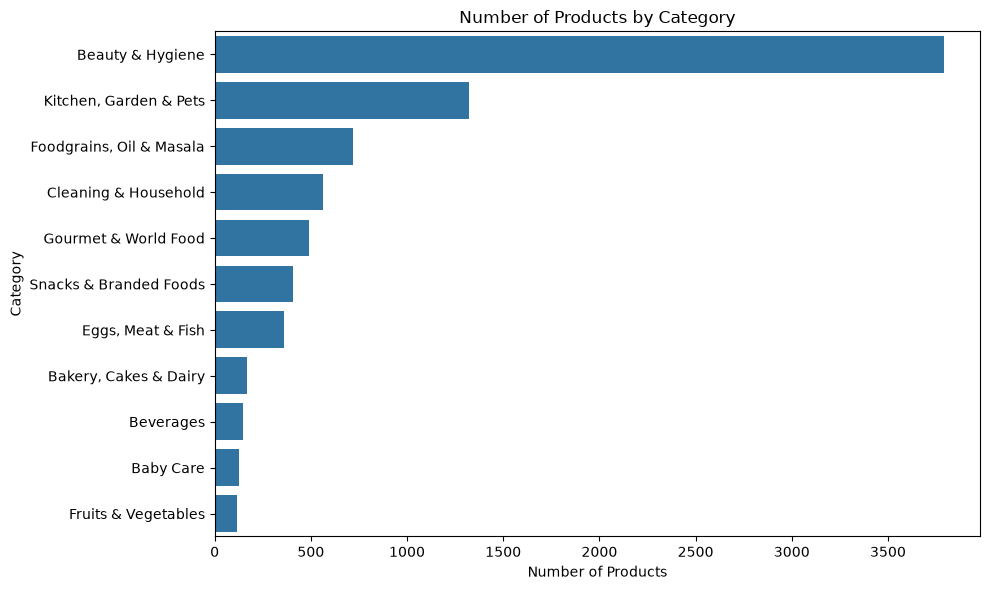

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Number of Products by Category")
plt.xlabel("Number of Products")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [27]:
category_percentage = (
    df["Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(category_percentage)

Category
Beauty & Hygiene            46.16
Kitchen, Garden & Pets      16.09
Foodgrains, Oil & Masala     8.75
Cleaning & Household         6.85
Gourmet & World Food         5.97
Snacks & Branded Foods       4.97
Eggs, Meat & Fish            4.39
Bakery, Cakes & Dairy        2.06
Beverages                    1.79
Baby Care                    1.55
Fruits & Vegetables          1.43
Name: proportion, dtype: float64


In [29]:
subcategory_counts = df["SubCategory"].value_counts().head(15)

print(subcategory_counts)

SubCategory
Face Care                 825
Supplements & Proteins    240
Face                      207
Body Care                 205
Shampoo & Conditioner     201
Ayurveda                  169
Men's Deodorants          165
Lips                      164
Eyes                      139
Nails                     122
Containers Sets           107
Women's Deodorants        105
Eau De Parfum             105
Glassware                 101
Aromatherapy               98
Name: count, dtype: int64


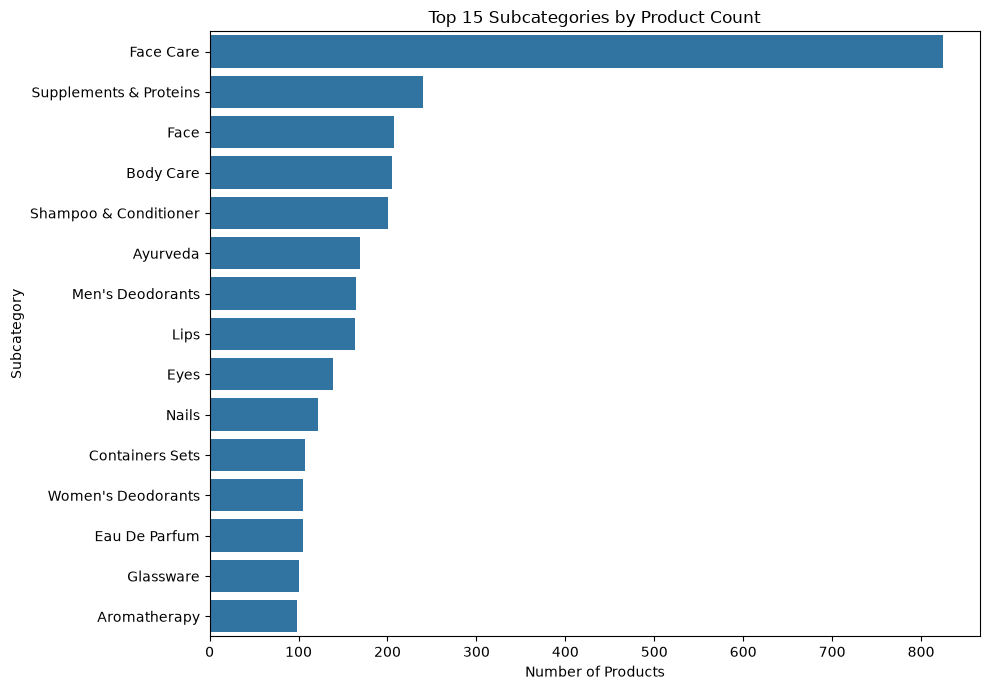

In [31]:
plt.figure(figsize=(10, 7))

sns.barplot(
    x=subcategory_counts.values,
    y=subcategory_counts.index
)

plt.title("Top 15 Subcategories by Product Count")
plt.xlabel("Number of Products")
plt.ylabel("Subcategory")

plt.tight_layout()
plt.show()

In [32]:
subcategory_percentage = (
    df["SubCategory"]
    .value_counts(normalize=True)
    .head(15)
    .mul(100)
    .round(2)
)

print(subcategory_percentage)

SubCategory
Face Care                 10.05
Supplements & Proteins     2.92
Face                       2.52
Body Care                  2.50
Shampoo & Conditioner      2.45
Ayurveda                   2.06
Men's Deodorants           2.01
Lips                       2.00
Eyes                       1.69
Nails                      1.49
Containers Sets            1.30
Women's Deodorants         1.28
Eau De Parfum              1.28
Glassware                  1.23
Aromatherapy               1.19
Name: proportion, dtype: float64


## Subcategory Analysis Insights

- Face Care is the largest subcategory with 825 products, representing 10.05% of the dataset.
- Supplements & Proteins is the second-largest subcategory with 240 products (2.92%).
- Several of the top subcategories belong to beauty, personal care, and wellness.
- The subcategory distribution supports the earlier finding that Beauty & Hygiene is the dominant product category.

In [34]:
brand_counts = df["Brand"].value_counts().head(15)

print(brand_counts)

Brand
Fresho              479
BB Royal            410
BB Home             183
Healthvit            98
Soulflower           88
DP                   88
GoodDiet             87
Lakme                84
Nivea                83
BIOTIQUE             79
Tasties              74
BB Popular           71
Fresho Signature     69
Titania              62
Aroma Magic          61
Name: count, dtype: int64


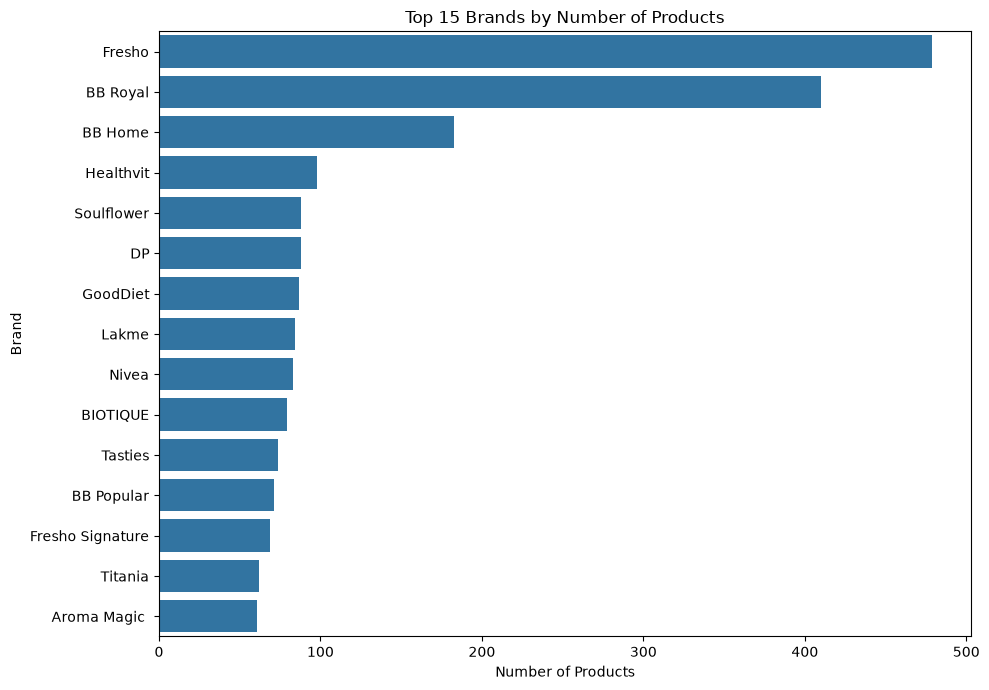

In [36]:
plt.figure(figsize=(10, 7))

sns.barplot(
    x=brand_counts.values,
    y=brand_counts.index
)

plt.title("Top 15 Brands by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()

In [38]:
brand_percentage = (
    df["Brand"]
    .value_counts(normalize=True)
    .head(15)
    .mul(100)
    .round(2)
)

print(brand_percentage)

Brand
Fresho              5.84
BB Royal            5.00
BB Home             2.23
Healthvit           1.19
Soulflower          1.07
DP                  1.07
GoodDiet            1.06
Lakme               1.02
Nivea               1.01
BIOTIQUE            0.96
Tasties             0.90
BB Popular          0.87
Fresho Signature    0.84
Titania             0.76
Aroma Magic         0.74
Name: proportion, dtype: float64


## Brand Analysis Insights

- Fresho has the largest product presence with 479 products (5.84%).
- BB Royal is the second-largest brand with 410 products (5.00%).
- Fresho and BB Royal together represent approximately 10.84% of the dataset.
- The remaining brands have relatively small individual shares, indicating a diverse product catalog.
- BigBasket-associated brands such as Fresho, BB Royal, and BB Home have a strong presence in the dataset.

In [40]:
price_stats = df[["Price", "DiscountPrice", "Discount_Percentage"]].describe()

print(price_stats.round(2))

          Price  DiscountPrice  Discount_Percentage
count   8208.00        8208.00              8208.00
mean     545.42         356.91                31.96
std      664.55         438.10                13.05
min        5.00           3.00                 0.00
25%      190.00         129.00                25.00
50%      360.00         238.00                30.00
75%      650.00         429.00                40.00
max    10140.00        7605.00                80.00


In [42]:
price_comparison = df[["Price", "DiscountPrice"]].mean()

print(price_comparison.round(2))

Price            545.42
DiscountPrice    356.91
dtype: float64


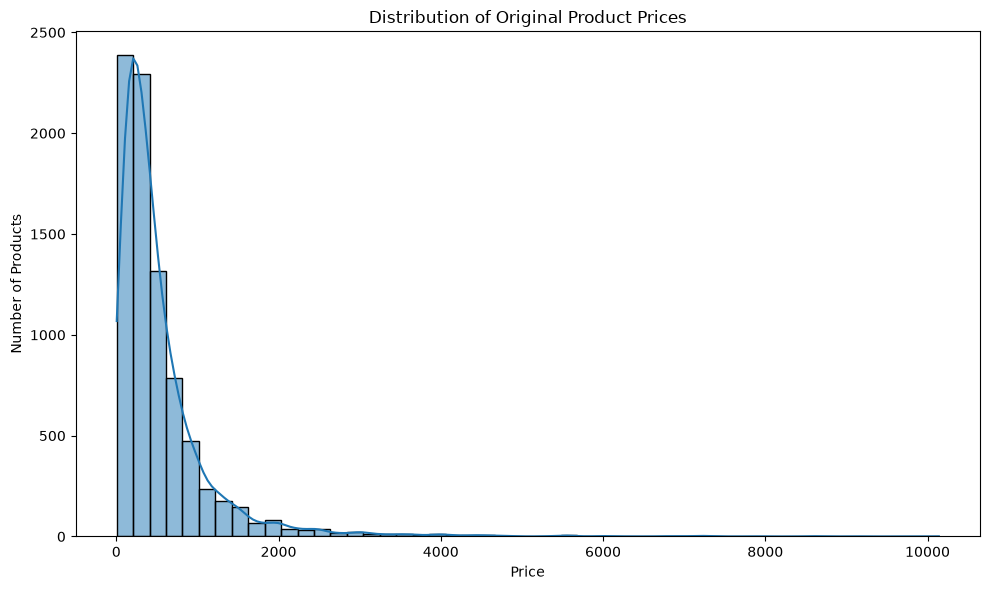

In [44]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["Price"],
    bins=50,
    kde=True
)

plt.title("Distribution of Original Product Prices")
plt.xlabel("Price")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

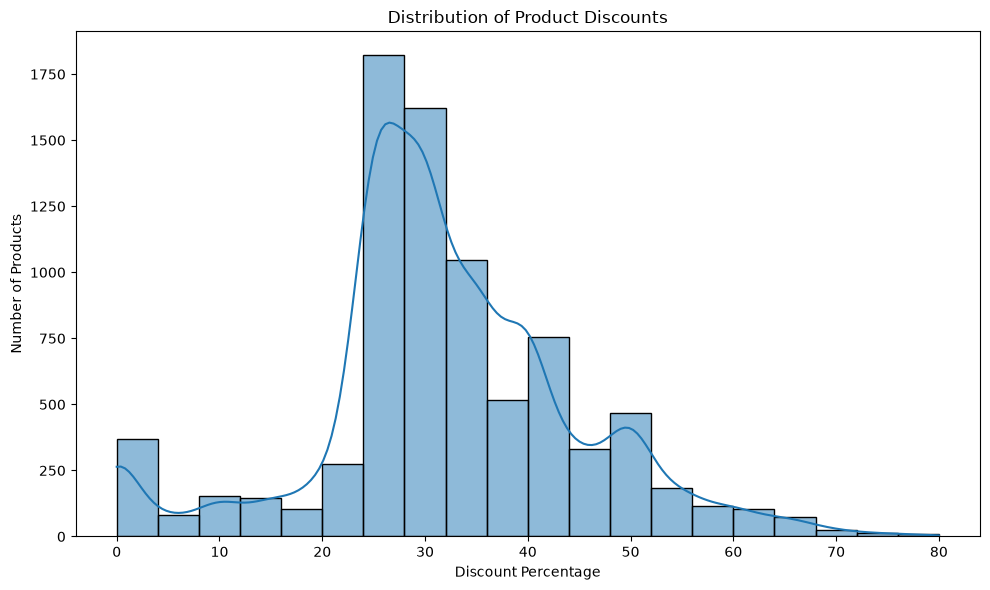

In [46]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["Discount_Percentage"],
    bins=20,
    kde=True
)

plt.title("Distribution of Product Discounts")
plt.xlabel("Discount Percentage")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

In [48]:
df["Savings"] = df["Price"] - df["DiscountPrice"]

print("Average savings per product: ₹",
      round(df["Savings"].mean(), 2))

print("Maximum savings on a product: ₹",
      round(df["Savings"].max(), 2))

Average savings per product: ₹ 188.51
Maximum savings on a product: ₹ 5146.0


## Price & Discount Analysis Insights

- The average original product price is ₹545.42, while the average discounted price is ₹356.91.
- Customers save an average of ₹188.51 per product.
- The average discount percentage is 31.96%, with a median discount of 30%.
- Discounts range from 0% to 80%.
- The maximum recorded saving is ₹5,146 on a single product.
- The pricing analysis indicates that promotional discounts can substantially reduce the effective purchase price of products.

In [50]:
category_discount = (
    df.groupby("Category")
    .agg(
        Product_Count=("ProductName", "count"),
        Average_Discount=("Discount_Percentage", "mean"),
        Average_Savings=("Savings", "mean")
    )
    .sort_values("Average_Discount", ascending=False)
)

print(category_discount.round(2))

                          Product_Count  Average_Discount  Average_Savings
Category                                                                  
Kitchen, Garden & Pets             1321             38.07           294.35
Fruits & Vegetables                 117             37.28            28.60
Cleaning & Household                562             36.43           190.37
Gourmet & World Food                490             31.93           173.90
Eggs, Meat & Fish                   360             31.56           219.86
Beauty & Hygiene                   3789             30.88           191.29
Foodgrains, Oil & Masala            718             29.78           105.75
Snacks & Branded Foods              408             26.23            59.91
Baby Care                           127             26.15           269.93
Bakery, Cakes & Dairy               169             25.77            52.24
Beverages                           147             23.35           105.45


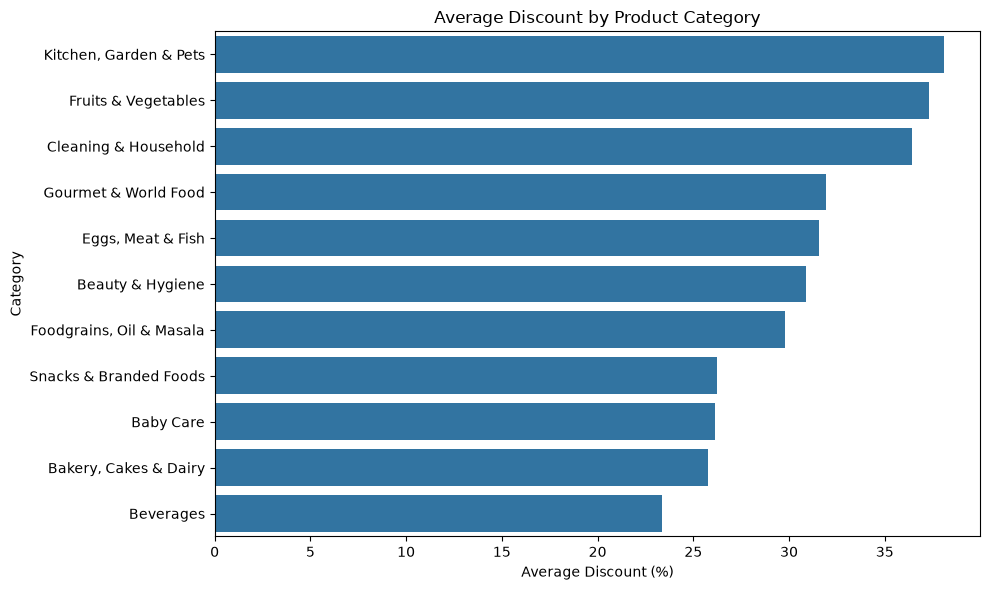

In [52]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_discount.reset_index(),
    x="Average_Discount",
    y="Category"
)

plt.title("Average Discount by Product Category")
plt.xlabel("Average Discount (%)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [54]:
category_savings = (
    df.groupby("Category")["Savings"]
    .sum()
    .sort_values(ascending=False)
)

print(category_savings.round(2))

Category
Beauty & Hygiene            724780.63
Kitchen, Garden & Pets      388834.41
Cleaning & Household        106986.89
Gourmet & World Food         85212.60
Eggs, Meat & Fish            79151.25
Foodgrains, Oil & Masala     75928.26
Baby Care                    34281.01
Snacks & Branded Foods       24444.39
Beverages                    15500.52
Bakery, Cakes & Dairy         8829.26
Fruits & Vegetables           3345.96
Name: Savings, dtype: float64


## Discount Analysis by Category

- Kitchen, Garden & Pets has the highest average discount at 38.07%.
- Fruits & Vegetables has a high average discount of 37.28%, but its average absolute savings are only ₹28.60 because the products are generally lower priced.
- Beauty & Hygiene generates the highest total customer savings at approximately ₹724,781 due to its large product volume.
- The analysis demonstrates that discount percentage and absolute monetary savings provide different business perspectives.
- Categories with larger product catalogs can generate greater total savings even when their average discount percentage is not the highest.

In [56]:
price_discount_corr = df[
    ["Price", "Discount_Percentage"]
].corr()

print(price_discount_corr.round(2))

                     Price  Discount_Percentage
Price                 1.00                 0.16
Discount_Percentage   0.16                 1.00


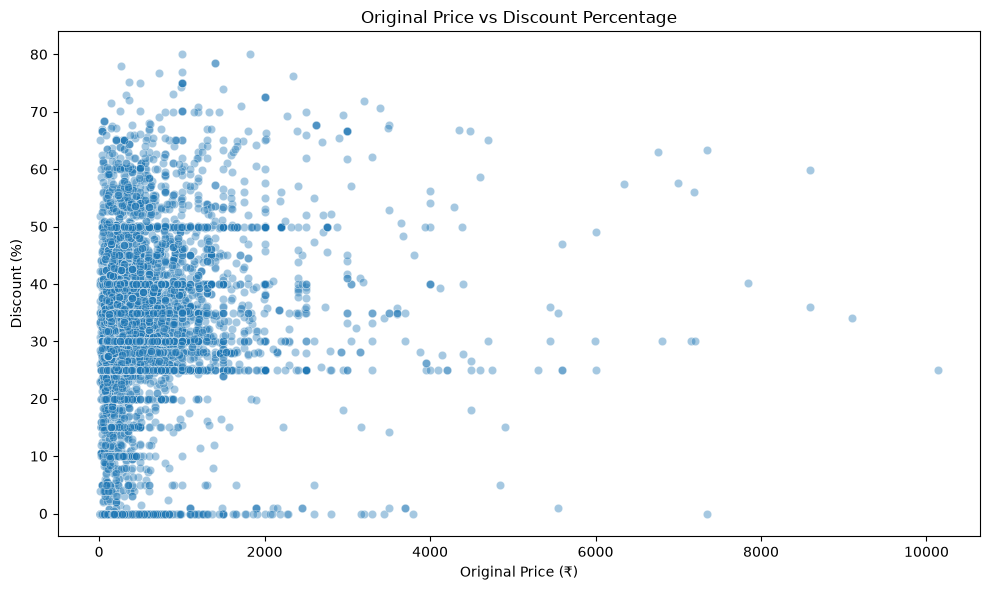

In [58]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Price",
    y="Discount_Percentage",
    alpha=0.4
)

plt.title("Original Price vs Discount Percentage")
plt.xlabel("Original Price (₹)")
plt.ylabel("Discount (%)")

plt.tight_layout()
plt.show()

In [60]:
df["Price_Group"] = pd.qcut(
    df["Price"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

price_group_discount = df.groupby(
    "Price_Group",
    observed=True
)["Discount_Percentage"].mean()

print(price_group_discount.round(2))

Price_Group
Low            27.92
Medium-Low     30.90
Medium-High    33.73
High           35.38
Name: Discount_Percentage, dtype: float64


## Price vs Discount Analysis

- The correlation between original price and discount percentage is 0.16, indicating a weak positive relationship.
- Average discount increases across the four price groups.
- Low-priced products receive an average discount of 27.92%.
- High-priced products receive an average discount of 35.38%.
- The results suggest that higher-priced products tend to have somewhat larger percentage discounts.
- However, the weak correlation indicates that price alone is not a strong predictor of discount percentage.
- Correlation indicates association and does not imply causation.

In [62]:
top_discounted = df[
    [
        "ProductName",
        "Brand",
        "Category",
        "Price",
        "DiscountPrice",
        "Discount_Percentage",
        "Savings"
    ]
].sort_values(
    "Discount_Percentage",
    ascending=False
).head(15)

print(top_discounted.to_string(index=False))

                                                                                       ProductName          Brand               Category  Price  DiscountPrice  Discount_Percentage  Savings
                                                                CMZ Plus Tablets - For Bone Health       Mojocare       Beauty & Hygiene  999.0         199.80            80.000000   799.20
                                                                       Flora Duo Eyeshadow Palette   ZUII ORGANIC       Beauty & Hygiene 1825.0         365.00            80.000000  1460.00
Flora Microwave Bowl Set - Green, Stainless Steel, Food Grade, Dishwasher Safe, Airtight, BPA Free        Jensons Kitchen, Garden & Pets 1395.0         299.00            78.566308  1096.00
 Flora Microwave Bowl Set - Blue, Stainless Steel, Food Grade, Dishwasher Safe, Airtight, BPA Free        Jensons Kitchen, Garden & Pets 1395.0         299.00            78.566308  1096.00
                                                       

In [64]:
top_savings = df[
    [
        "ProductName",
        "Brand",
        "Category",
        "Price",
        "DiscountPrice",
        "Discount_Percentage",
        "Savings"
    ]
].sort_values(
    "Savings",
    ascending=False
).head(15)

print(top_savings.to_string(index=False))

                                                               ProductName          Brand               Category  Price  DiscountPrice  Discount_Percentage  Savings
                    4 Burner Glaze MS Cook Top Gas Stove - Manual Ignition    Surya Flame Kitchen, Garden & Pets 8595.0        3449.00            59.872019  5146.00
                    3 Burner Glaze MS Cook Top Gas Stove - Manual Ignition    Surya Flame Kitchen, Garden & Pets 7345.0        2699.00            63.253914  4646.00
                      Aluminium Non-Stick Ceramic Coated Magic Pan - Brown         Nirlon Kitchen, Garden & Pets 6755.0        2499.00            63.005181  4256.00
                                                     Extra Light Olive Oil         Disano   Gourmet & World Food 7195.0        3165.80            56.000000  4029.20
                                                     Extra Light Olive Oil Rafael Salgado   Gourmet & World Food 6999.0        2970.00            57.565366  4029.00
          

## Most Discounted Products Analysis

- Some products receive discounts as high as 80%.
- The highest percentage discount does not necessarily result in the highest monetary savings.
- High-priced products such as gas stoves and cookware generate the largest absolute savings.
- The maximum customer saving in the dataset is ₹5,146.
- This demonstrates the importance of analyzing both discount percentage and absolute savings when evaluating promotional impact.

In [66]:
category_price = (
    df.groupby("Category")
    .agg(
        Product_Count=("ProductName", "count"),
        Average_Price=("Price", "mean"),
        Average_Discount_Price=("DiscountPrice", "mean"),
        Average_Savings=("Savings", "mean")
    )
    .sort_values("Average_Price", ascending=False)
)

print(category_price.round(2))

                          Product_Count  Average_Price  \
Category                                                 
Baby Care                           127         894.27   
Kitchen, Garden & Pets             1321         739.68   
Eggs, Meat & Fish                   360         695.81   
Beauty & Hygiene                   3789         580.70   
Cleaning & Household                562         498.51   
Gourmet & World Food                490         477.15   
Beverages                           147         393.54   
Foodgrains, Oil & Masala            718         334.14   
Snacks & Branded Foods              408         202.58   
Bakery, Cakes & Dairy               169         188.98   
Fruits & Vegetables                 117          77.17   

                          Average_Discount_Price  Average_Savings  
Category                                                           
Baby Care                                 624.34           269.93  
Kitchen, Garden & Pets                   

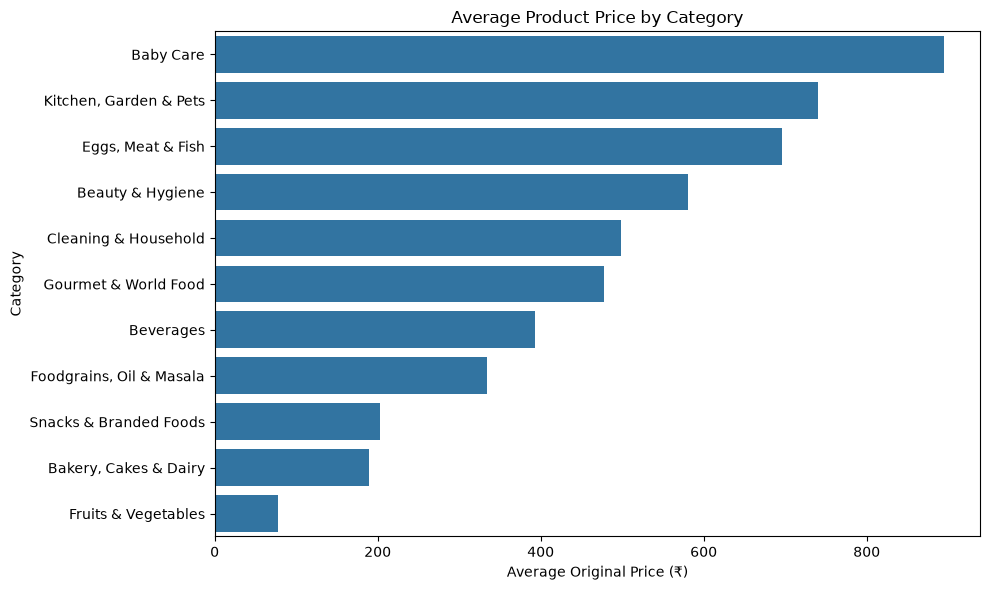

In [68]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_price.reset_index(),
    x="Average_Price",
    y="Category"
)

plt.title("Average Product Price by Category")
plt.xlabel("Average Original Price (₹)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [70]:
print(
    category_price[
        ["Average_Price", "Average_Discount_Price", "Average_Savings"]
    ].head(10).round(2)
)

                          Average_Price  Average_Discount_Price  \
Category                                                          
Baby Care                        894.27                  624.34   
Kitchen, Garden & Pets           739.68                  445.33   
Eggs, Meat & Fish                695.81                  475.94   
Beauty & Hygiene                 580.70                  389.41   
Cleaning & Household             498.51                  308.14   
Gourmet & World Food             477.15                  303.25   
Beverages                        393.54                  288.10   
Foodgrains, Oil & Masala         334.14                  228.39   
Snacks & Branded Foods           202.58                  142.67   
Bakery, Cakes & Dairy            188.98                  136.73   

                          Average_Savings  
Category                                   
Baby Care                          269.93  
Kitchen, Garden & Pets             294.35  
Eggs, Meat & Fish  

## Category vs Price Analysis

- Baby Care has the highest average original product price at ₹894.27.
- Kitchen, Garden & Pets has the second-highest average price at ₹739.68.
- Kitchen, Garden & Pets provides the highest average customer savings of ₹294.35 per product.
- Fruits & Vegetables is the least expensive category, with an average price of ₹77.17.
- Higher product prices do not always result in the highest customer savings; discount strategy also plays an important role.

In [72]:
brand_analysis = (
    df.groupby("Brand")
    .agg(
        Product_Count=("ProductName", "count"),
        Average_Price=("Price", "mean"),
        Average_Discount_Price=("DiscountPrice", "mean"),
        Average_Discount=("Discount_Percentage", "mean"),
        Average_Savings=("Savings", "mean")
    )
)

brand_analysis = brand_analysis[
    brand_analysis["Product_Count"] >= 20
].sort_values(
    "Product_Count",
    ascending=False
)

print(brand_analysis.head(20).round(2))

                  Product_Count  Average_Price  Average_Discount_Price  \
Brand                                                                    
Fresho                      479         538.38                  367.69   
BB Royal                    410         329.40                  225.63   
BB Home                     183         440.64                  247.65   
Healthvit                    98         626.57                  420.73   
DP                           88         384.81                  206.24   
Soulflower                   88         704.60                  476.85   
GoodDiet                     87         191.63                  128.85   
Lakme                        84         433.71                  309.81   
Nivea                        83         400.72                  265.92   
BIOTIQUE                     79         353.33                  251.21   
Tasties                      74         155.66                  104.03   
BB Popular                   71       

In [74]:
top_discount_brands = brand_analysis.sort_values(
    "Average_Discount",
    ascending=False
).head(15)

print(top_discount_brands.round(2))

                    Product_Count  Average_Price  Average_Discount_Price  \
Brand                                                                      
Nirlon                         34        2678.85                  979.29   
Lattafa                        34        2167.62                 1083.81   
Spantra                        26         445.15                  222.58   
ExclusiveLane                  25        1793.92                  896.96   
Natures Velvet                 41        1256.10                  673.34   
Polyset                        50         423.80                  233.20   
Princeware                     52         248.67                  135.87   
DP                             88         384.81                  206.24   
Klassic                        38         556.16                  317.84   
BB Home                       183         440.64                  247.65   
Himalayan Organics             33        1094.64                  608.05   
Kitchen Esse

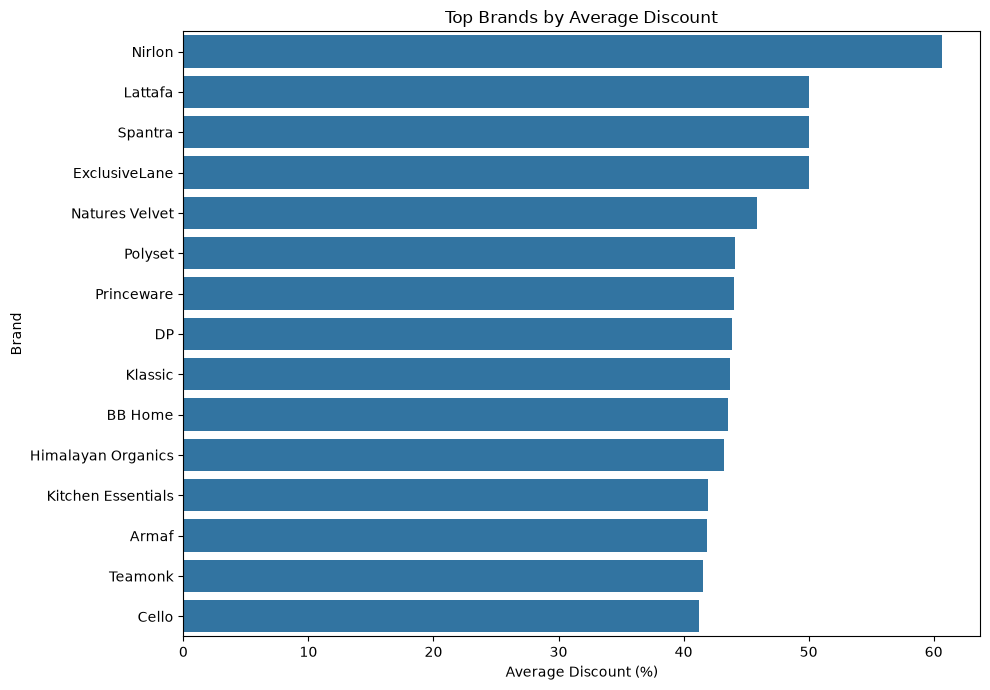

In [76]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_discount_brands.reset_index(),
    x="Average_Discount",
    y="Brand"
)

plt.title("Top Brands by Average Discount")
plt.xlabel("Average Discount (%)")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()

## Brand vs Price & Discount Analysis

- Nirlon has the highest average discount among brands with at least 20 products, at 60.67%.
- Nirlon also provides the highest average monetary savings of approximately ₹1,699.56 per product.
- Lattafa and ExclusiveLane have an average discount of 50%.
- HAZEL has a relatively high average product price of ₹1,009.54 but a much lower average discount of 15.25%.
- The analysis shows that higher product prices do not necessarily result in higher discounts.
- Brand-level pricing and promotional strategies vary significantly.
- A minimum product-count threshold of 20 was used to make brand comparisons more reliable.

In [78]:
print("===== BIGBASKET EDA SUMMARY =====")

print("Total Products:", len(df))
print("Unique Products:", df["ProductName"].nunique())
print("Unique Brands:", df["Brand"].nunique())
print("Categories:", df["Category"].nunique())
print("Subcategories:", df["SubCategory"].nunique())

print("\nAverage Original Price: ₹", round(df["Price"].mean(), 2))
print("Average Discount Price: ₹", round(df["DiscountPrice"].mean(), 2))
print("Average Discount: ", round(df["Discount_Percentage"].mean(), 2), "%")
print("Average Savings: ₹", round(df["Savings"].mean(), 2))

===== BIGBASKET EDA SUMMARY =====
Total Products: 8208
Unique Products: 6769
Unique Brands: 842
Categories: 11
Subcategories: 334

Average Original Price: ₹ 545.42
Average Discount Price: ₹ 356.91
Average Discount:  31.96 %
Average Savings: ₹ 188.51


In [80]:
largest_category = df["Category"].value_counts().idxmax()
largest_category_count = df["Category"].value_counts().max()

print(
    "Largest Category:",
    largest_category,
    "with",
    largest_category_count,
    "products"
)

Largest Category: Beauty & Hygiene with 3789 products


In [82]:
highest_discount_category = (
    df.groupby("Category")["Discount_Percentage"]
    .mean()
    .idxmax()
)

highest_discount_value = (
    df.groupby("Category")["Discount_Percentage"]
    .mean()
    .max()
)

print(
    "Highest Average Discount Category:",
    highest_discount_category,
    "-",
    round(highest_discount_value, 2),
    "%"
)

Highest Average Discount Category: Kitchen, Garden & Pets - 38.07 %


In [84]:
largest_brand = df["Brand"].value_counts().idxmax()
largest_brand_count = df["Brand"].value_counts().max()

print(
    "Largest Brand:",
    largest_brand,
    "with",
    largest_brand_count,
    "products"
)

Largest Brand: Fresho with 479 products


In [86]:
max_saving_product = df.loc[df["Savings"].idxmax()]

print("\nHighest Customer Saving:")
print("Product:", max_saving_product["ProductName"])
print("Brand:", max_saving_product["Brand"])
print("Original Price: ₹", max_saving_product["Price"])
print("Discount Price: ₹", max_saving_product["DiscountPrice"])
print("Savings: ₹", max_saving_product["Savings"])
print("Discount:", round(max_saving_product["Discount_Percentage"], 2), "%")


Highest Customer Saving:
Product: 4 Burner Glaze MS Cook Top Gas Stove - Manual Ignition
Brand: Surya Flame
Original Price: ₹ 8595.0
Discount Price: ₹ 3449.0
Savings: ₹ 5146.0
Discount: 59.87 %


In [88]:
print(df.columns.tolist())

['ProductName', 'Brand', 'Price', 'DiscountPrice', 'Image_Url', 'Quantity', 'Category', 'SubCategory', 'Absolute_Url', 'Discount_Percentage', 'Savings', 'Price_Group']


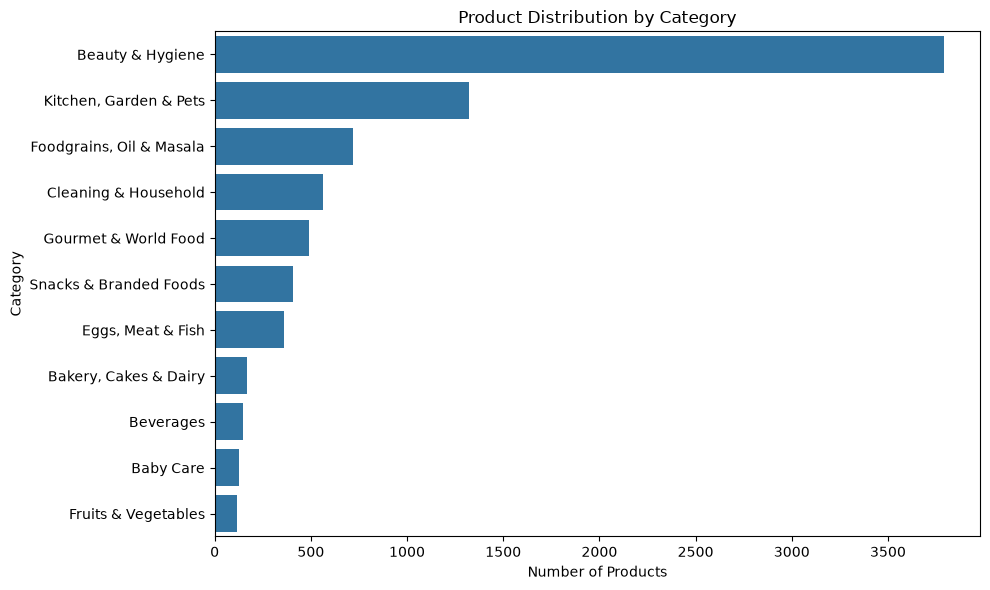

In [90]:
category_counts = df["Category"].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=category_counts.values, y=category_counts.index)

plt.title("Product Distribution by Category")
plt.xlabel("Number of Products")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

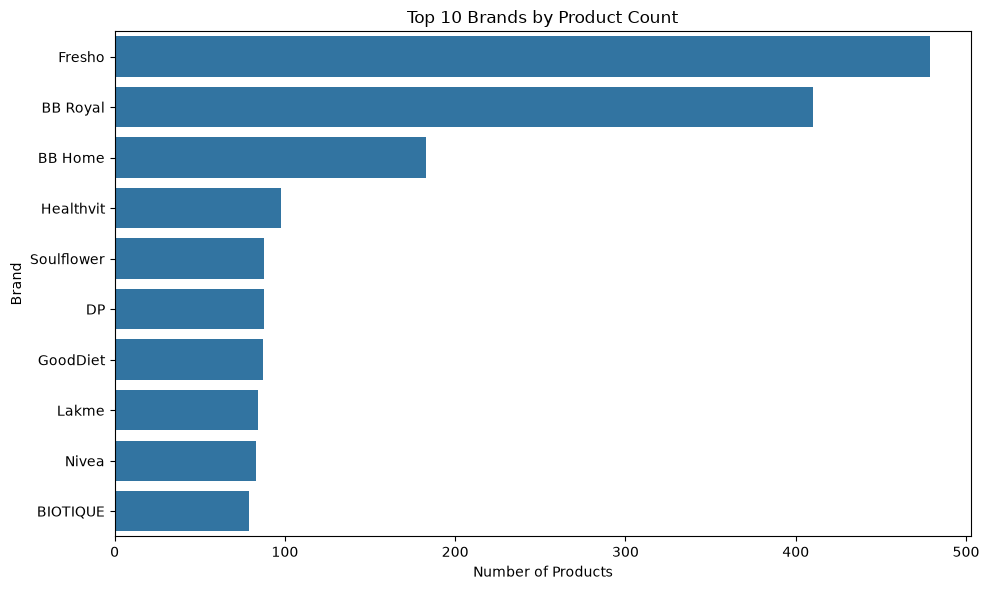

In [92]:
top_brands = df["Brand"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_brands.values, y=top_brands.index)

plt.title("Top 10 Brands by Product Count")
plt.xlabel("Number of Products")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

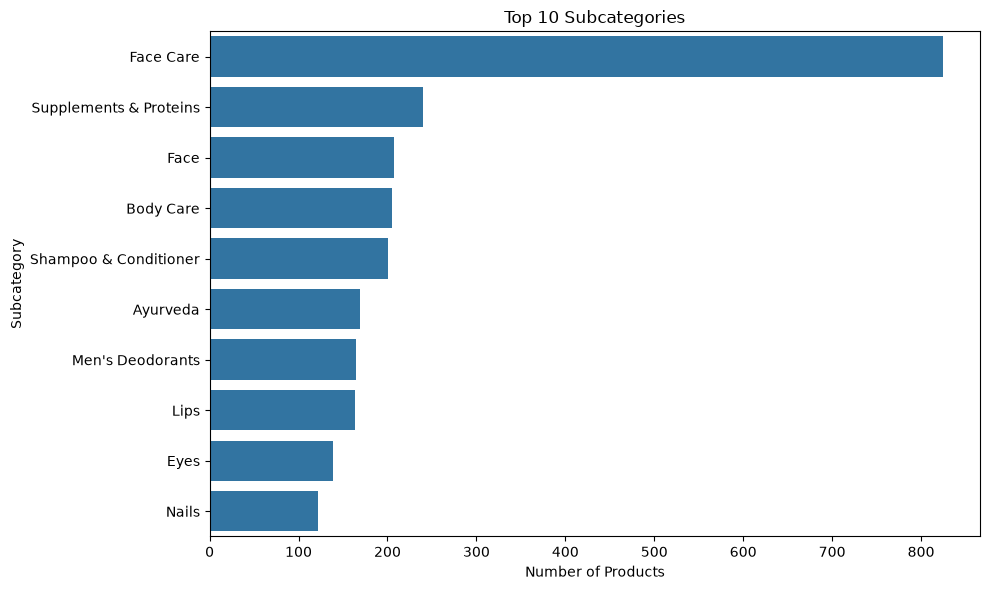

In [94]:
top_subcategories = df["SubCategory"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_subcategories.values, y=top_subcategories.index)

plt.title("Top 10 Subcategories")
plt.xlabel("Number of Products")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.show()

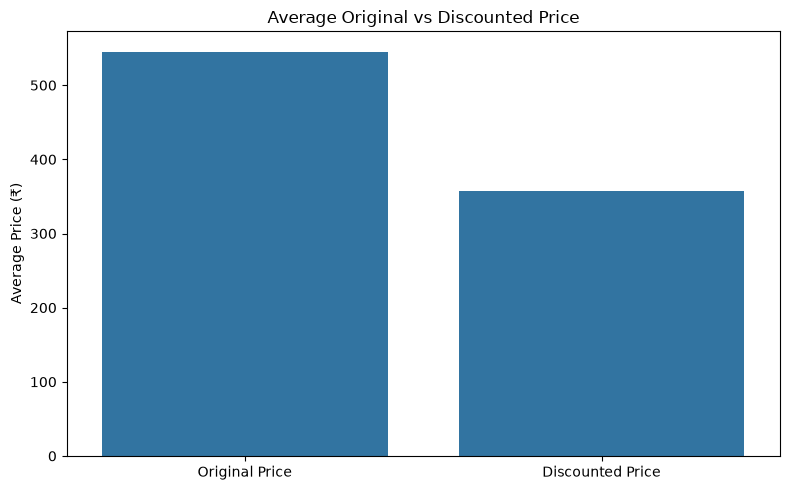

In [96]:
price_data = pd.DataFrame({
    "Price Type": ["Original Price", "Discounted Price"],
    "Average Price": [
        df["Price"].mean(),
        df["DiscountPrice"].mean()
    ]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=price_data, x="Price Type", y="Average Price")

plt.title("Average Original vs Discounted Price")
plt.ylabel("Average Price (₹)")
plt.xlabel("")
plt.tight_layout()
plt.show()

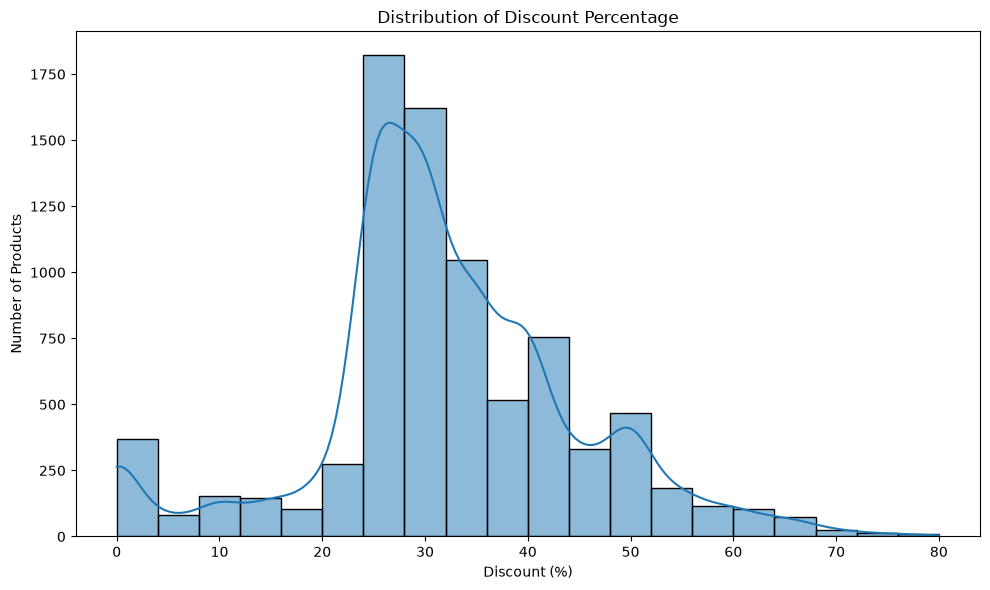

In [98]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["Discount_Percentage"],
    bins=20,
    kde=True
)

plt.title("Distribution of Discount Percentage")
plt.xlabel("Discount (%)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

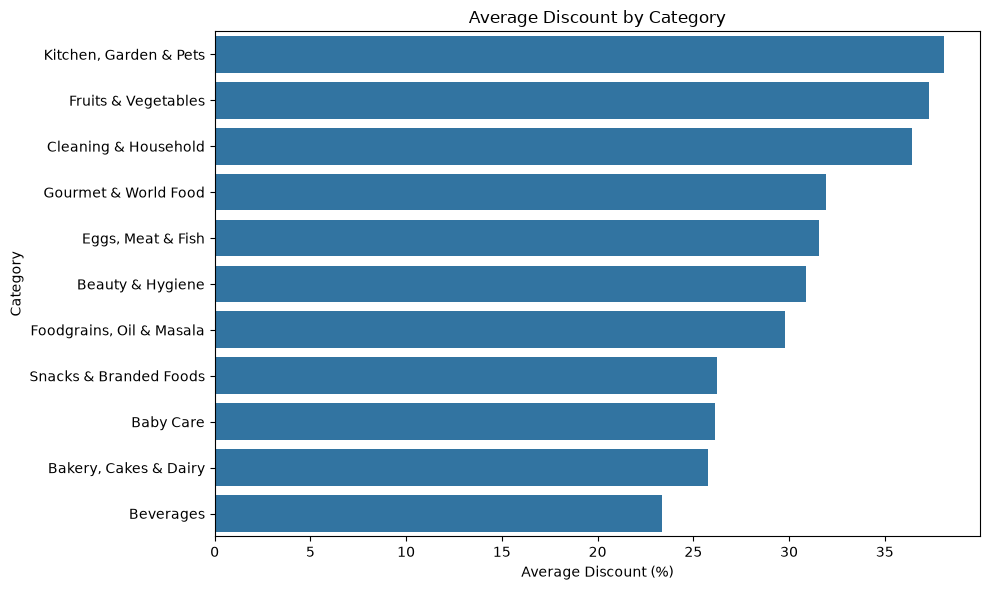

In [100]:
category_discount_plot = (
    df.groupby("Category")["Discount_Percentage"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=category_discount_plot.values,
    y=category_discount_plot.index
)

plt.title("Average Discount by Category")
plt.xlabel("Average Discount (%)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

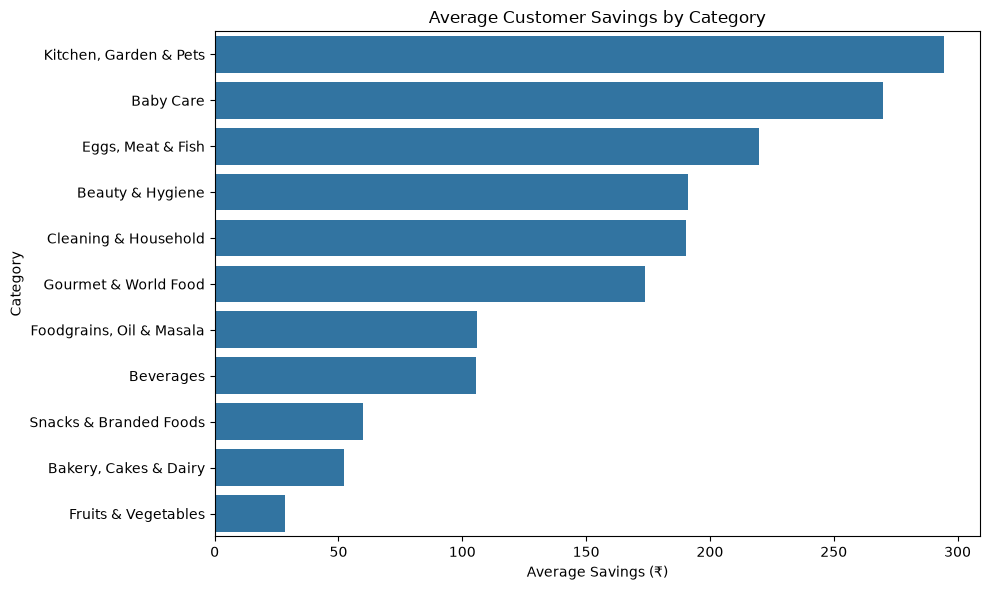

In [102]:
category_savings_plot = (
    df.groupby("Category")["Savings"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=category_savings_plot.values,
    y=category_savings_plot.index
)

plt.title("Average Customer Savings by Category")
plt.xlabel("Average Savings (₹)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

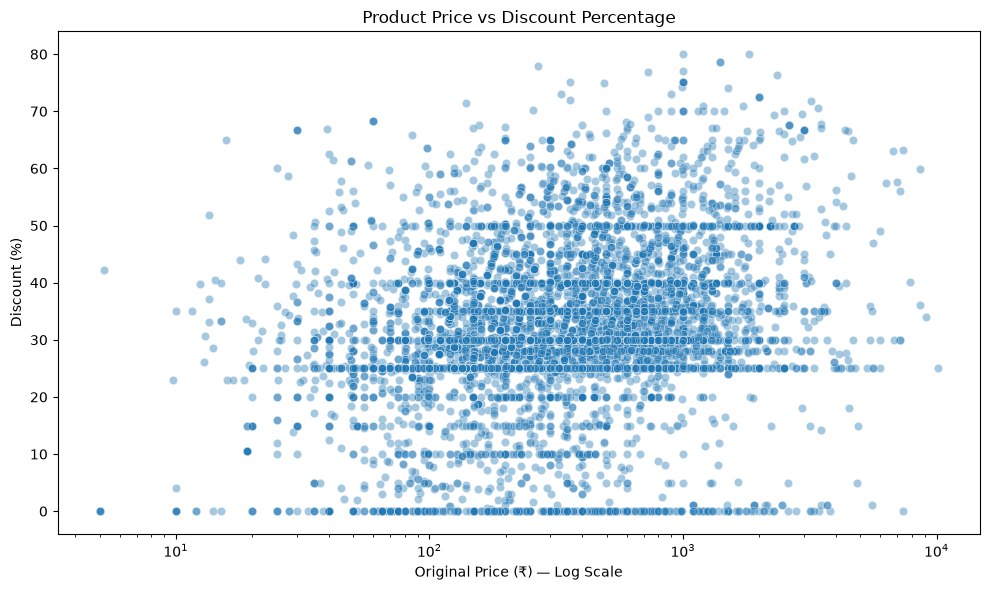

In [103]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Price",
    y="Discount_Percentage",
    alpha=0.4
)

plt.xscale("log")

plt.title("Product Price vs Discount Percentage")
plt.xlabel("Original Price (₹) — Log Scale")
plt.ylabel("Discount (%)")

plt.tight_layout()
plt.show()